<a href="https://colab.research.google.com/github/thmller/Lab_Neural_Networks/blob/main/Lab_NeuralNetworks_Hmwk1_solved.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Part 0 – First exploration (EDA) (2 points)
1. Load both files. Give the number of rows and columns of each.

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt



customers = pd.read_csv('customers.csv')
monthly_usage = pd.read_csv('monthly_usage.csv')
print("Customers shape " + str(customers.shape))
print("Monthly usage shape " + str(monthly_usage.shape))


Customers shape (1225, 9)
Monthly usage shape (6689, 9)


2. For each column, give its type and its number of missing values.

In [ ]:
print("Customers.csv")
print("# of missing values per column: \n" + str(customers.isna().sum()))
print('_________________________________')
print("datatype for each column: ")
print(customers.dtypes)
print('=================================================================')


print("Monthly_usage.csv")
print("# of missing values per column: \n" + str(monthly_usage.isna().sum()))
print('_________________________________')
print("datatype for each column: ")
print(monthly_usage.dtypes)

Customers.csv
# of missing values per column: 
customer_id            0
gender                24
date_of_birth         43
city                  25
contract_type          0
tenure_months         48
monthly_charge_usd    36
num_complaints         0
churn                  0
dtype: int64
_________________________________
datatype for each column: 
customer_id            object
gender                 object
date_of_birth          object
city                   object
contract_type          object
tenure_months         float64
monthly_charge_usd    float64
num_complaints          int64
churn                  object
dtype: object
Monthly_usage.csv
# of missing values per column: 
cust_no              0
month                0
minutes_day        134
minutes_evening      0
minutes_night        0
total_minutes        0
sms_count            0
data_volume          0
data_unit            0
dtype: int64
_________________________________
datatype for each column: 
cust_no              int64
month      

3. For each text column (gender, city, contract_type, churn), list the distinct values. What do
you notice?

In [ ]:
print(customers.value_counts("gender"))
print()
print(customers.value_counts("city"))
print()
print(customers.value_counts("contract_type"))
print()
print(customers.value_counts("churn"))

# Also possible to use: customers['gender'].unique()
# I prefered the representation of the data of .value_counts()

gender
M         573
F         488
 M         26
F          23
male       22
Male       16
m          14
female     14
Female     13
f          12
Name: count, dtype: int64

city
Kinshasa       322
Addis Ababa    272
Lubumbashi     133
Gondar          80
Bahir Dar       79
Goma            76
Hawassa         67
Kisangani       52
Kinshasa        17
ADDIS ABABA     14
KINSHASA        14
addis ababa     13
kinshasa        10
kisangani        9
Gonder           8
goma             7
Addis-Ababa      6
Bahirdar         5
lubumbashi       5
Awassa           4
Lubumbachi       4
bahir dar        3
Name: count, dtype: int64

contract_type
Prepaid      819
Postpaid     310
PREPAID       24
Pre-paid      23
prepaid       15
POSTPAID      15
Post-paid     12
postpaid       7
Name: count, dtype: int64

churn
No     1053
Yes     172
Name: count, dtype: int64


4. Show describe() for the numeric columns. Which minimum or maximum values are
impossible in real life?

In [ ]:
print("customer.csv: ")
print(print(customers.describe()))

#Comments:
# tenure months: -12 tuenure months not possible,
# monthly charge: (max vs min) is too broad (8.43 vs 9999)

print("=========================================")
print("monthly_usage.csv: ")
print(print(monthly_usage.describe()))
#Comments:
# minutes day
# minutes evening
# minutes night
# total minutes
# data volume

customer.csv: 
       tenure_months  monthly_charge_usd  num_complaints
count    1177.000000         1189.000000     1225.000000
mean       40.056075           74.616156        0.888163
std        24.036082          707.148578        0.967477
min       -12.000000            8.430000        0.000000
25%        19.000000           16.670000        0.000000
50%        39.000000           21.890000        1.000000
75%        61.000000           31.410000        1.000000
max        96.000000         9999.000000        5.000000
None
monthly_usage.csv: 
           cust_no  minutes_day  minutes_evening  minutes_night  \
count  6689.000000  6555.000000      6689.000000    6689.000000   
mean    604.090597   220.926087       143.854448      44.267977   
std     348.967627   138.023117        91.879193      29.008907   
min       1.000000    13.100000         0.000000       0.000000   
25%     300.000000   127.600000        81.900000      25.100000   
50%     603.000000   186.700000       122.300

5. Draw a histogram of monthly_charge_usd and a box plot of data_volume.

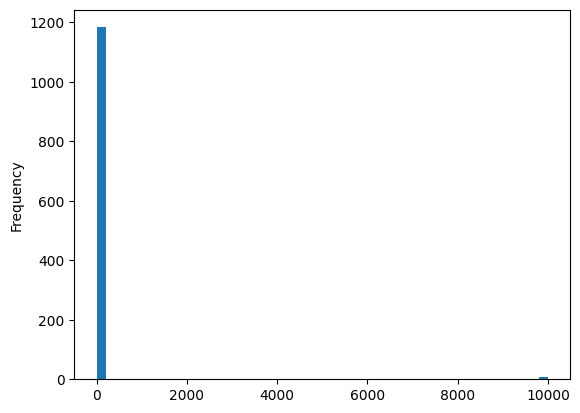

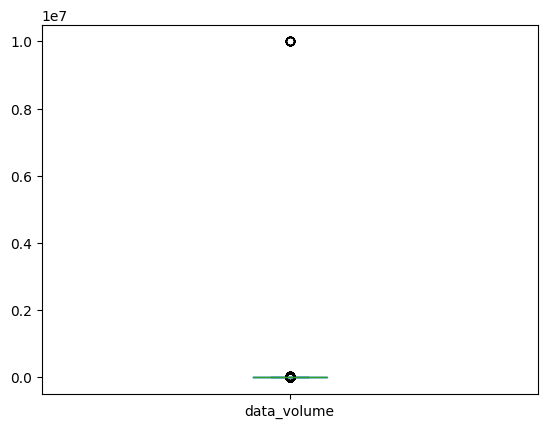

In [ ]:
customers["monthly_charge_usd"].plot.hist(bins=50)
plt.show()

monthly_usage["data_volume"].plot.box()
plt.show()


# Part 1 – Data cleaning (5 points)
1.1 Duplicates. Count and remove the exact duplicate rows in both files. Then check that each
customer_id appears only once, and each (cust_no, month) pair only once.

In [ ]:

# duplicate rows
print(customers.duplicated().sum())
print(monthly_usage.duplicated().sum())

customers_no_duplicates = customers.drop_duplicates()
monthly_no_duplicates = monthly_usage.drop_duplicates()

# customer_id should be true and thus distinct
print(customers_no_duplicates["customer_id"].is_unique)

# (cust_no, month) should appear only once in monthly usage
print(monthly_no_duplicates.duplicated(subset=["cust_no", "month"]).sum())

25
30
True
0


1.2 Inconsistent data.
Standardize the categories:

*   gender → only M or F.
*   city → one correct spelling per city (for example KINSHASA, kinshasa and Kinshasa all
become Kinshasa). At the end there must be exactly 8 cities.
*   contract_type → only Prepaid or Postpaid.



In [ ]:
# Delete any row without gender
customers_no_duplicates = customers_no_duplicates.dropna(subset=['gender'])

# different entries with 'F' or 'M'
customers_no_duplicates['gender'] = customers_no_duplicates['gender'].replace({
    'Male': 'M',
    'male': 'M',
    'Female': 'F',
    'female': 'F',
    'm': 'M',
    'f': 'F',
    ' M': 'M',
    'F ':'F'
})
#Checking
print(customers_no_duplicates.value_counts("gender"))
print('--------------------------------------------')
customers_no_duplicates["city"] = (
    customers_no_duplicates["city"]
    .str.strip()
    .str.title()
)

customers_no_duplicates['city'] = customers_no_duplicates['city'].replace({
    'Lubumbachi': 'Lubumbashi',
    'Addis-Ababa': 'Addis Ababa',
    'Hawassa': 'Awassa',
    'Bahirdar': 'Bahir Dar',
    'Gondar': 'Gonder'
})
print(customers_no_duplicates["city"].value_counts())
print('--------------------------------------------')
customers_no_duplicates["contract_type"] = (
    customers_no_duplicates["contract_type"]
    .str.strip()
    .str.title()
)
customers_no_duplicates['contract_type'] = customers_no_duplicates['contract_type'].replace({
    'Pre-Paid': 'Prepaid',
    'Post-Paid': 'Postpaid'
})
print(customers_no_duplicates["contract_type"].value_counts())
print("Negative Tenure Months: "+str((customers_no_duplicates["tenure_months"] < 0).sum()))


gender
M    636
F    540
Name: count, dtype: int64
--------------------------------------------
city
Kinshasa       347
Addis Ababa    296
Lubumbashi     138
Gonder          84
Bahir Dar       80
Goma            80
Awassa          67
Kisangani       60
Name: count, dtype: int64
--------------------------------------------
contract_type
Prepaid     845
Postpaid    331
Name: count, dtype: int64
Negative Tenure Months: 8


1.3 Invalid values. Find the values that are impossible and replace them with a missing value (NaN):

*   a negative tenure_months;
*   a monthly_charge_usd of 9999 (a placeholder value of the billing system);
*   a date_of_birth that gives an age under 16 or over 100 years;
*   a data_volume that is negative or larger than 1,000,000.

How many values did you replace for each rule?




In [ ]:
# Tenure Months: 8 found
customers_no_duplicates.loc[customers_no_duplicates["tenure_months"] < 0, "tenure_months"] = np.nan
# Checking
print("Negative Tenure Months: "+str((customers_no_duplicates["tenure_months"] < 0).sum()))

#------------------------------------------------------------------------------------------
# Monthly_charge_usd: 6 found
print("Negative Tenure Months: "+str((customers_no_duplicates["monthly_charge_usd"] == 9999).sum()))

customers_no_duplicates.loc[customers_no_duplicates["monthly_charge_usd"] == 9999, "monthly_charge_usd"] = np.nan

#------------------------------------------------------------------------------------------
# Date_of_birth: 5 found

customers_no_duplicates["date_of_birth"] = pd.to_datetime(customers_no_duplicates["date_of_birth"], errors="coerce")

today = pd.Timestamp.today().normalize()

too_young = customers_no_duplicates["date_of_birth"] > today - pd.DateOffset(years=16)   # under 16
too_old   = customers_no_duplicates["date_of_birth"] < today - pd.DateOffset(years=100)  # over 100

print("Not valid ages: "+ str(too_young.sum()+ too_old.sum()))  # check how many you're replacing

customers_no_duplicates.loc[too_young | too_old, "date_of_birth"] = pd.NaT
#------------------------------------------------------------------------------------------
# Data_volume: 32 found
print("Data volume: "+str((monthly_no_duplicates["data_volume"] < 0).sum()+(monthly_no_duplicates["data_volume"] > 1000000).sum() ))

monthly_no_duplicates.loc[monthly_no_duplicates["data_volume"] <0, "data_volume"] = np.nan
monthly_no_duplicates.loc[monthly_no_duplicates["data_volume"] > 1000000, "data_volume"] = np.nan
#------------------------------------------------------------------------------------------
# Checking
print("Data volume: "+str((monthly_no_duplicates["data_volume"] < 0).sum()+(monthly_no_duplicates["data_volume"] > 1000000).sum() ))

Negative Tenure Months: 0
Negative Tenure Months: 6
Not valid ages: 5
Data volume: 32
Data volume: 0


1.4 Missing values.
* For tenure_months and monthly_charge_usd: compute the skewness of each column, then
fill with the mean or the median. Justify your choice.
* For gender and city: fill with the mode.
* For date_of_birth: fill with the median date.
* For minutes_day: do not use the mean. Find an exact way to rebuild the missing values from
the other minute columns. How many values can you rebuild?
* Why do we not simply delete every row with a missing value here?

In [ ]:
cols = ["tenure_months", "monthly_charge_usd"]

# Skewness of each column
print(customers_no_duplicates[cols].skew())

customers_no_duplicates["tenure_months"] = customers_no_duplicates["tenure_months"].fillna(customers_no_duplicates["tenure_months"].mean())
customers_no_duplicates["monthly_charge_usd"] = customers_no_duplicates["monthly_charge_usd"].fillna(customers_no_duplicates["monthly_charge_usd"].median())

customers_no_duplicates["gender"] = customers_no_duplicates["gender"].fillna(customers_no_duplicates["gender"].mode())
customers_no_duplicates["city"] = customers_no_duplicates["city"].fillna(customers_no_duplicates["city"].mode())

customers_no_duplicates["date_of_birth"] = customers_no_duplicates["date_of_birth"].fillna(customers_no_duplicates["date_of_birth"].median())

mask = (
    monthly_no_duplicates["minutes_day"].isna()
    & monthly_no_duplicates["total_minutes"].notna()
    & monthly_no_duplicates["minutes_evening"].notna()
    & monthly_no_duplicates["minutes_night"].notna()
)
monthly_no_duplicates.loc[mask, "minutes_day"] = (
    monthly_no_duplicates.loc[mask, "total_minutes"]
    - monthly_no_duplicates.loc[mask, "minutes_evening"]
    - monthly_no_duplicates.loc[mask, "minutes_night"]
)
print(mask.sum(), "values rebuilt")

tenure_months         0.176939
monthly_charge_usd    0.992415
dtype: float64
0 values rebuilt


1.5 Noisy data – smoothing by binning. Sort monthly_charge_usd and divide it into 10 equalfrequency bins (pd.qcut). Create a new column charge_smoothed where each value is replaced by
the mean of its bin. Show the 10 bin means.

In [ ]:
# Equal-frequency binning into 10 bins (qcut sorts the values internally)
bins = pd.qcut(customers_no_duplicates["monthly_charge_usd"], q=10, duplicates="drop")

# Replace each value with the mean of its bin
customers_no_duplicates["charge_smoothed"] = customers_no_duplicates.groupby(bins, observed=True)["monthly_charge_usd"].transform("mean")

# Show the 10 bin means
bin_means = customers_no_duplicates.groupby(bins, observed=True)["monthly_charge_usd"].mean()
print(bin_means)

monthly_charge_usd
(8.429, 13.78]     12.122269
(13.78, 15.96]     14.950252
(15.96, 17.73]     16.841217
(17.73, 19.82]     18.733390
(19.82, 22.215]    21.014701
(22.215, 24.43]    23.724082
(24.43, 28.73]     26.604103
(28.73, 32.88]     30.895254
(32.88, 37.27]     34.895983
(37.27, 81.7]      43.551102
Name: monthly_charge_usd, dtype: float64


1.6 Outliers. First convert data_volume to MB for every row (look at data_unit). Then compute the
IQR fence (Q3 + 1.5 × IQR) of the data volume. How many points are above the fence? Are they
errors or real heavy users? What would you do with them, and why?

In [ ]:
# Convert data_volume to MB
unit = monthly_no_duplicates["data_unit"].astype(str).str.strip().str.upper()
factor = unit.map({"MB": 1, "GB": 1024})
monthly_no_duplicates["data_volume_mb"] = monthly_no_duplicates["data_volume"] * factor

print(unit.value_counts(dropna=False))

# IQR fence
q1 = monthly_no_duplicates["data_volume_mb"].quantile(0.25)
q3 = monthly_no_duplicates["data_volume_mb"].quantile(0.75)
iqr = q3 - q1
fence = q3 + 1.5 * iqr

outliers = monthly_no_duplicates[monthly_no_duplicates["data_volume_mb"] > fence]
print(f"Q1={q1:.1f}, Q3={q3:.1f}, IQR={iqr:.1f}, fence={fence:.1f} MB")
print(len(outliers), "points above the fence")

# Inspect them
print(outliers["data_volume_mb"].describe())
print(outliers["cust_no"].nunique(), "distinct customers")
print(outliers.groupby("cust_no").size().sort_values(ascending=False).head())

data_unit
MB    4424
GB    2235
Name: count, dtype: int64
Q1=1565.0, Q3=4674.4, IQR=3109.4, fence=9338.6 MB
407 points above the fence
count      407.000000
mean     14122.126509
std       5447.898855
min       9344.523000
25%      10826.613500
50%      12583.179000
75%      15480.005000
max      53536.768000
Name: data_volume_mb, dtype: float64
131 distinct customers
cust_no
591     6
216     6
112     6
1091    6
970     6
dtype: int64


/tmp/ipykernel_611/674852045.py:4: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  monthly_no_duplicates["data_volume_mb"] = monthly_no_duplicates["data_volume"] * factor


Part 2 – Data integration (4 points)
The two files come from two different systems. You must merge them into one table with one row
per customer.
1. The two files do not use the same ID format (CUST-00052 vs 52). Create a common key in
customers.csv.
2. Aggregation: monthly_usage.csv has up to 6 rows per customer. Group it by customer and
compute, for each customer: the number of months recorded, and the average per month of
each minute column, sms_count and the data volume in MB.
3. Merge the aggregated usage into the customer table with a left join.
4. Answer with numbers:
– How many customers have no usage records? What value do you give to their usage
columns, and why?
– How many cust_no exist in the usage file but not in the CRM file? What do you do with
them?
5. Check that the final table has exactly one row per customer.

In [ ]:
customers_no_duplicates = customers_no_duplicates.copy()
customers_no_duplicates["cust_no"] = (
    customers_no_duplicates["customer_id"].str.extract(r"(\d+)")[0].astype(int)
)

print(customers_no_duplicates["cust_no"].is_unique)   # True
print(customers_no_duplicates["cust_no"].dtype, monthly_no_duplicates["cust_no"].dtype)

# Aggregation: months recorded + monthly averages per customer

monthly_no_duplicates = monthly_no_duplicates.copy()

unit = monthly_no_duplicates["data_unit"].astype(str).str.strip().str.upper()
factor = unit.map({"MB": 1, "GB": 1024})
monthly_no_duplicates["data_volume_mb"] = monthly_no_duplicates["data_volume"] * factor

print(monthly_no_duplicates["data_volume_mb"].isna().sum(), "missing")

usage_agg = (
    monthly_no_duplicates.groupby("cust_no")
    .agg(
        n_months=("month", "nunique"),
        minutes_day=("minutes_day", "mean"),
        minutes_evening=("minutes_evening", "mean"),
        minutes_night=("minutes_night", "mean"),
        total_minutes=("total_minutes", "mean"),
        sms_count=("sms_count", "mean"),
        data_volume_mb=("data_volume_mb", "mean"),
    )
    .reset_index()
)

# Left join
final = customers_no_duplicates.merge(usage_agg, on="cust_no", how="left")

# Customers without usage records
no_usage = final["n_months"].isna().sum()
print(no_usage, "customers have no usage records")
final["n_months"] = final["n_months"].fillna(0).astype(int)   # months recorded = 0

# cust_no in the usage file but not in the CRM file
orphans = set(usage_agg["cust_no"]) - set(customers_no_duplicates["cust_no"])
print(len(orphans), "cust_no in usage but not in CRM")

# One row per customer
print(final["cust_no"].is_unique, len(final) == len(customers_no_duplicates))

True
int64 int64
32 missing
40 customers have no usage records
39 cust_no in usage but not in CRM
True True


# Part 3 – Data transformation (5 points)
3.1 Attribute construction. From date_of_birth, create age (in years, on 30 June 2026). Then
create is_senior (1 if age ≥ 60, else 0). How many senior customers are there?

In [ ]:
final["date_of_birth"] = pd.to_datetime(final["date_of_birth"], errors="coerce")

ref = pd.Timestamp("2026-06-30")
dob = final["date_of_birth"]

# Completed years on 30 June 2026 (subtract 1 if the birthday hasn't happened yet that year)
had_birthday = (dob.dt.month < ref.month) | ((dob.dt.month == ref.month) & (dob.dt.day <= ref.day))
final["age"] = ref.year - dob.dt.year - (~had_birthday).astype(int)

final["is_senior"] = (final["age"] >= 60).astype(int)

print(final["is_senior"].sum(), "senior customers")
print(final["age"].describe())

62 senior customers
count    1176.000000
mean       37.392007
std        12.639630
min        18.000000
25%        28.000000
50%        37.000000
75%        45.000000
max        85.000000
Name: age, dtype: float64


3.2 Generalization. Create a country column from city, using this concept hierarchy: Kinshasa,
Lubumbashi, Goma and Kisangani → DR Congo; Addis Ababa, Gondar, Bahir Dar and Hawassa →
Ethiopia. Compute the churn rate per country.

In [ ]:
city_to_country = {
    "Kinshasa": "DR Congo", "Lubumbashi": "DR Congo", "Goma": "DR Congo", "Kisangani": "DR Congo",
    "Addis Ababa": "Ethiopia", "Gondar": "Ethiopia", "Bahir Dar": "Ethiopia", "Hawassa": "Ethiopia",
}

final["country"] = final["city"].astype(str).str.strip().str.title().map(city_to_country)

# Check that every city was mapped
print(final["country"].isna().sum(), "cities not mapped")
print(final.loc[final["country"].isna(), "city"].unique())

# Churn rate per country (churn is Yes/No)
final["churn_flag"] = (final["churn"].astype(str).str.strip().str.lower() == "yes").astype(int)

churn_rate = final.groupby("country")["churn_flag"].agg(customers="count", churned="sum", churn_rate="mean")
churn_rate["churn_rate"] = (churn_rate["churn_rate"] * 100).round(2)   # in %
print(churn_rate)

175 cities not mapped
[nan 'Gonder' 'Awassa']
          customers  churned  churn_rate
country                                 
DR Congo        625       81       12.96
Ethiopia        376       59       15.69


3.3 Normalization. For the numeric columns (tenure_months, monthly_charge_usd,
num_complaints, age and the usage averages):
* apply min-max normalization to [0, 1], and check the new minimum and maximum;
* apply z-score normalization, and check the new mean and standard deviation;
* explain in two sentences why a distance-based model (for example k-NN) needs this step

In [ ]:
num_cols = [
    "tenure_months", "monthly_charge_usd", "num_complaints", "age",
    "minutes_day", "minutes_evening", "minutes_night", "total_minutes",
    "sms_count", "data_volume_mb",
]

# Min-max normalization to [0, 1]
minmax = (final[num_cols] - final[num_cols].min()) / (final[num_cols].max() - final[num_cols].min())
minmax.columns = [c + "_minmax" for c in num_cols]

# Z-score normalization
zscore = (final[num_cols] - final[num_cols].mean()) / final[num_cols].std(ddof=0)
zscore.columns = [c + "_z" for c in num_cols]

final = pd.concat([final, minmax, zscore], axis=1)

#Checking
print(minmax.agg(["min", "max"]).T)
print(zscore.agg(["mean", lambda s: s.std(ddof=0)]).T.round(6))

                           min  max
tenure_months_minmax       0.0  1.0
monthly_charge_usd_minmax  0.0  1.0
num_complaints_minmax      0.0  1.0
age_minmax                 0.0  1.0
minutes_day_minmax         0.0  1.0
minutes_evening_minmax     0.0  1.0
minutes_night_minmax       0.0  1.0
total_minutes_minmax       0.0  1.0
sms_count_minmax           0.0  1.0
data_volume_mb_minmax      0.0  1.0
                      mean  <lambda>
tenure_months_z        0.0       1.0
monthly_charge_usd_z   0.0       1.0
num_complaints_z       0.0       1.0
age_z                 -0.0       1.0
minutes_day_z          0.0       1.0
minutes_evening_z      0.0       1.0
minutes_night_z       -0.0       1.0
total_minutes_z       -0.0       1.0
sms_count_z            0.0       1.0
data_volume_mb_z      -0.0       1.0


3.4 Discretization.
* age_group: < 18, 18–44, 44–60, > 60.
* tenure_group: 0–12, 13–24, 25–48, > 48 months.
Compute the churn rate per tenure_group. What do you conclude about new customers?

In [ ]:
# age_group: < 18, 18-44, 45-60, > 60
final["age_group"] = pd.cut(
    final["age"],
    bins=[-float("inf"), 17, 44, 60, float("inf")],
    labels=["<18", "18-44", "45-60", ">60"],
)

# tenure_group: 0-12, 13-24, 25-48, > 48 months
final["tenure_group"] = pd.cut(
    final["tenure_months"],
    bins=[-1, 12, 24, 48, float("inf")],
    labels=["0-12", "13-24", "25-48", ">48"],
)

print(final["age_group"].value_counts().sort_index())
print(final["tenure_group"].value_counts().sort_index())

# Churn rate per tenure group
churn_by_tenure = final.groupby("tenure_group", observed=True)["churn_flag"].agg(
    customers="count", churned="sum", churn_rate="mean"
)
churn_by_tenure["churn_rate"] = (churn_by_tenure["churn_rate"] * 100).round(2)
print(churn_by_tenure)

age_group
<18        0
18-44    861
45-60    263
>60       52
Name: count, dtype: int64
tenure_group
0-12     178
13-24    175
25-48    385
>48      438
Name: count, dtype: int64
              customers  churned  churn_rate
tenure_group                                
0-12                178       58       32.58
13-24               175       35       20.00
25-48               385       51       13.25
>48                 438       22        5.02


# Part 4 – Data reduction (3 points)
1. Redundant features. Draw the correlation matrix (heatmap) of the usage averages and
monthly_charge_usd. Which columns are almost perfectly correlated? Which column is an
exact sum of others, and can be removed without losing information?

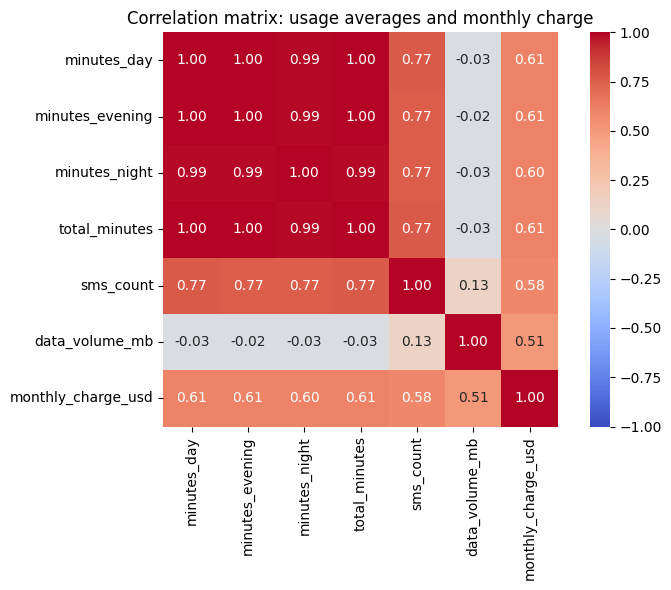

minutes_day      total_minutes      0.999525
minutes_evening  total_minutes      0.998651
minutes_day      minutes_evening    0.997069
minutes_night    total_minutes      0.991910
minutes_day      minutes_night      0.990315
minutes_evening  minutes_night      0.987327
dtype: float64
4.547473508864641e-13


In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt

cols = ["minutes_day", "minutes_evening", "minutes_night", "total_minutes",
        "sms_count", "data_volume_mb", "monthly_charge_usd"]

corr = final[cols].corr()

plt.figure(figsize=(8, 6))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, square=True)
plt.title("Correlation matrix: usage averages and monthly charge")
plt.tight_layout()
plt.show()

# Pairs with |correlation| > 0.9
pairs = corr.where(~np.tril(np.ones(corr.shape, dtype=bool))).stack()
print(pairs[pairs.abs() > 0.9].sort_values(ascending=False))

# total minutes = sum
diff = final["total_minutes"] - final[["minutes_day", "minutes_evening", "minutes_night"]].sum(axis=1, skipna=False)
print(diff.abs().max())

2. PCA (dimensionality reduction). Standardize the 6 usage averages (minutes day, evening,
night, total, SMS, data), then apply a PCA.
* Give the variance explained by each component, and the cumulative variance.
* How many components do you need to keep 90%, then 95%, of the information?

In [ ]:
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

if "total_minutes" not in final.columns:
    final["total_minutes"] = final[["minutes_day", "minutes_evening", "minutes_night"]].sum(axis=1, skipna=False)

usage_cols = ["minutes_day", "minutes_evening", "minutes_night", "total_minutes", "sms_count", "data_volume_mb"]

#only customers with complete usage data
X = final[usage_cols].dropna()
print(X.shape[0], "customers used for PCA")

# Standardize
X_std = StandardScaler().fit_transform(X)
pca = PCA().fit(X_std)

result = pd.DataFrame({
    "component": [f"PC{i+1}" for i in range(len(usage_cols))],
    "variance_explained": pca.explained_variance_ratio_,
    "cumulative": pca.explained_variance_ratio_.cumsum(),
})
print(result.round(4))

# Number of components for 90% and 95%
cum = pca.explained_variance_ratio_.cumsum()
print("Components for 90%:", (cum >= 0.90).argmax() + 1)
print("Components for 95%:", (cum >= 0.95).argmax() + 1)

1136 customers used for PCA
  component  variance_explained  cumulative
0       PC1              0.7719      0.7719
1       PC2              0.1717      0.9436
2       PC3              0.0535      0.9971
3       PC4              0.0025      0.9995
4       PC5              0.0005      1.0000
5       PC6              0.0000      1.0000
Components for 90%: 2
Components for 95%: 3


3. Size. Compare the memory size of the two raw files with the size of your final table
(memory_usage(deep=True)). By how much did you reduce the data?

In [ ]:
def mb(df):
    return df.memory_usage(deep=True).sum() / 1024**2

raw_customers = mb(customers)
raw_monthly = mb(monthly_usage)
raw_total = raw_customers + raw_monthly
final_size = mb(final)

print(f"customers raw:     {raw_customers:.3f} MB")
print(f"monthly_usage raw: {raw_monthly:.3f} MB")
print(f"raw total:         {raw_total:.3f} MB")
print(f"final table:       {final_size:.3f} MB")
print(f"reduction:         {(1 - final_size / raw_total) * 100:.1f} %")

customers raw:     0.415 MB
monthly_usage raw: 1.040 MB
raw total:         1.455 MB
final table:       0.693 MB
reduction:         52.4 %


4. Think ahead. In the next chapter we will split the data into a training set and a test set. Why
should the mean, the median and the min/max used in this exercise be computed on the
training set only?

# Answer:
Because the test set is meant to simulate new, unseen customers. If the statistics are computed on the full dataset, information from the test rows leaks into the training process, a problem called data leakage.

Leakage inflates results. A mean, median, min or max computed on all the data contains information about the test rows. The model is then trained on data prepared with knowledge of the test set, so its test score looks better than its real performance on future data.
The test set must be treated like future data. When the model is deployed, new customers arrive one at a time and no one knows their mean or range in advance. The only honest preparation is to learn the statistics from the training data and apply those same fixed values to the test set (fit on train, transform on both).
The same applies to every step that learns from the data: filling missing values with the mean or median, min-max and z-score scaling, PCA, and the bin edges for discretization. The test set may have a value outside the training min/max (so its scaled value can fall outside [0, 1]), and that is correct, because it is exactly what would happen with real new customers.